<a href="https://colab.research.google.com/github/Lillie-Walden/Lab-4/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`)
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [3]:
# Import data from the GitHub repository
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv'
df = pd.read_csv(url)

# 1. Preview the dataframe
print("--- FIRST 5 ROWS ---")
display(df.head())

# 2. Basic dataset info
print("\n--- DATAFRAME INFO ---")
df.info()

# 3. Summary statistics (profiling)
print("\n--- SUMMARY STATISTICS ---")
display(df.describe())

# 4. Check for missing values
print("\n--- MISSING VALUES PER COLUMN ---")
print(df.isnull().sum())

# 5. Check for duplicate records
print(f"\nTotal duplicate rows: {df.duplicated().sum()}")

--- FIRST 5 ROWS ---


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0



--- DATAFRAME INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB

--- SUMMARY STATISTICS ---


,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000



--- MISSING VALUES PER COLUMN ---
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

Total duplicate rows: 3


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response:
1.1. A couple things stand out in the intitial preview. The minimum income is -65600 which is invalid because income should not be negative. The maximum age is 132, where that is unrealistic for the customer base. The maximum number of accounts is 3345, which is probably an input error because it is such a high value. There are also a few missing values and also duplicate values. The female column is an object type, where is should be binary or integer. This means there are probably mixed formats that need to be standardized.



# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [4]:
# 2.1 Check for and remove outliers
# Filters based on profiling observations:
# - Income must be non-negative
# - Age should be realistic (e.g., less than 110 years)
# - num_accts should be realistic (e.g., less than 50)
df_clean = df.copy()
df_clean = df_clean[df_clean['income'] >= 0]
df_clean = df_clean[df_clean['age'] < 110]
df_clean = df_clean[df_clean['num_accts'] < 50]

# 2.2 Address missing data
# Since there are only 2 missing values in 'new_car', dropping these records is a clean approach.
df_clean = df_clean.dropna(subset=['new_car'])

# Remove any duplicated rows
df_clean = df_clean.drop_duplicates()

# 2.3 Remove unhelpful or post-call variables
# - 'customer_id' is just an identifier.
# - 'product' is only determined AFTER the customer answers the call.
drop_cols = ['customer_id', 'product']
df_clean = df_clean.drop(columns=drop_cols)

# 2.4 Verify the clean dataframe
print(f"Original shape: {df.shape}")
print(f"Cleaned shape: {df_clean.shape}")
print("\nMissing values remaining:")
print(df_clean.isnull().sum())
print("\nSummary of cleaned numeric features:")
display(df_clean.describe())

Original shape: (29504, 15)
Cleaned shape: (29495, 13)

Missing values remaining:
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
dtype: int64

Summary of cleaned numeric features:


,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
count,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000,29495.000000
mean,0.546669,33776.323445,34.770232,1.915443,1.141041,0.210375,0.681132,0.240787,1.468215,0.956365,2.345313,0.091100
std,0.497826,29374.630821,11.354514,0.658239,0.348070,0.407582,0.466046,0.427568,1.234684,1.483834,1.200659,0.287756
min,0.000000,2760.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000
50%,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000
75%,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000
max,1.000000,159450.000000,74.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,8.000000,1.000000


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response:
2.5.
1. I first, filtered out any outliers that were bad data like the negative variables, unrealistic age, or the extreme values.
2. I also got rid of the missing data rows because there were only two and I thought that dropping them would be the most beneficial.
3. Finally, I removed the three completely identical rows so that I could prevent any duplication errors when analyzing the data further.



2.6. I removed the variables customer id, and product because customer id was a unirue numerical identifier that provided no value to the data for analysis. I also removed the product variable because this is all data that is used after the customer answers the call, whereas we are looking at information before the call is made. Therefore, this is no help to us.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [5]:
# Change 'answered' to a boolean (True/False) type
df_clean['answered'] = df_clean['answered'].astype(bool)

# Convert 'new_car' (which was a float) into an integer type now that missing values are removed
df_clean['new_car'] = df_clean['new_car'].astype(int)

# Display data types and verify updates
print(df_clean.dtypes)
display(df_clean.head())

answered            bool
income             int64
female            object
age                int64
job                int64
num_dependents     int64
rent               int64
own_res            int64
new_car            int64
chk_acct           int64
sav_acct           int64
num_accts          int64
mobile             int64
dtype: object


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
3,False,4330,0,24,2,2,1,0,0,1,3,1,0
4,False,4330,0,22,2,1,1,0,0,3,0,0,0
6,False,4330,0,22,2,1,1,0,0,3,0,0,0


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [15]:
# Inspect the 'female' column unique values
print("Unique values in 'female' before cleanup:", df_clean['female'].unique())

# Map potential values (such as '0', '1', 'M', 'F', 'female', etc.) to standard binary categories (0 and 1)
# Let's map typical representations
female_mapping = {
    '0': 0, '1': 1,
    0: 0, 1: 1,
    'M': 0, 'F': 1,
    'male': 0, 'female': 1,
    'Male': 0, 'Female': 1
}
df_clean['female'] = df_clean['female'].map(female_mapping).fillna(0).astype(int)

# Convert appropriate variables to categorical type
df_clean['female'] = df_clean['female'].astype('category')
df_clean['job'] = df_clean['job'].astype('category')
df_clean['chk_acct'] = df_clean['chk_acct'].astype('category')
df_clean['sav_acct'] = df_clean['sav_acct'].astype('category')

# Verify the updated data types and distribution
print(df_clean.dtypes)
print(df_clean['female'].value_counts())

Unique values in 'female' before cleanup: ['0', '1', 'M']
Categories (3, object): ['0', '1', 'M']
answered              bool
income               int64
female            category
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object
female
0    27897
1     1598
Name: count, dtype: int64


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



/tmp/ipykernel_2930/2023341193.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='answered', y='income', palette='Set2')


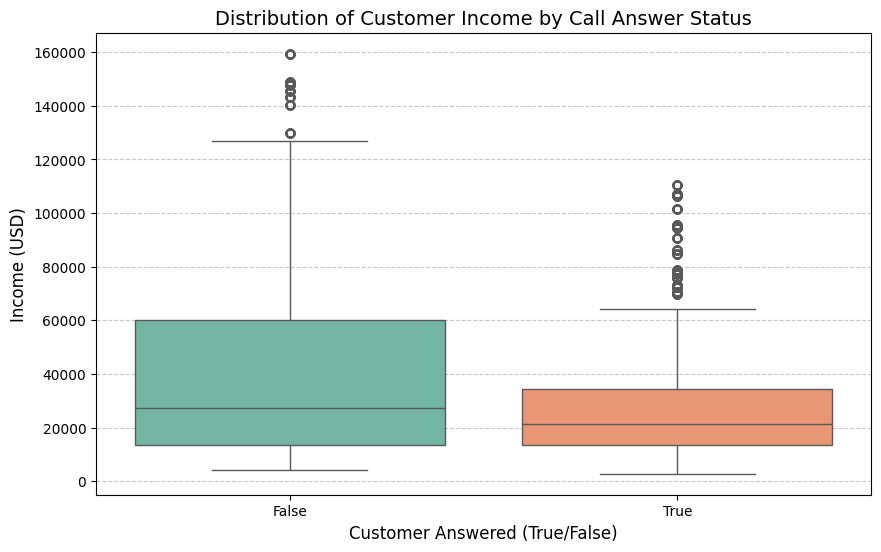

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Chart 3.1: Income distribution vs. Answered (Box Plot)
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='answered', y='income', palette='Set2')
plt.title('Distribution of Customer Income by Call Answer Status', fontsize=14)
plt.xlabel('Customer Answered (True/False)', fontsize=12)
plt.ylabel('Income (USD)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

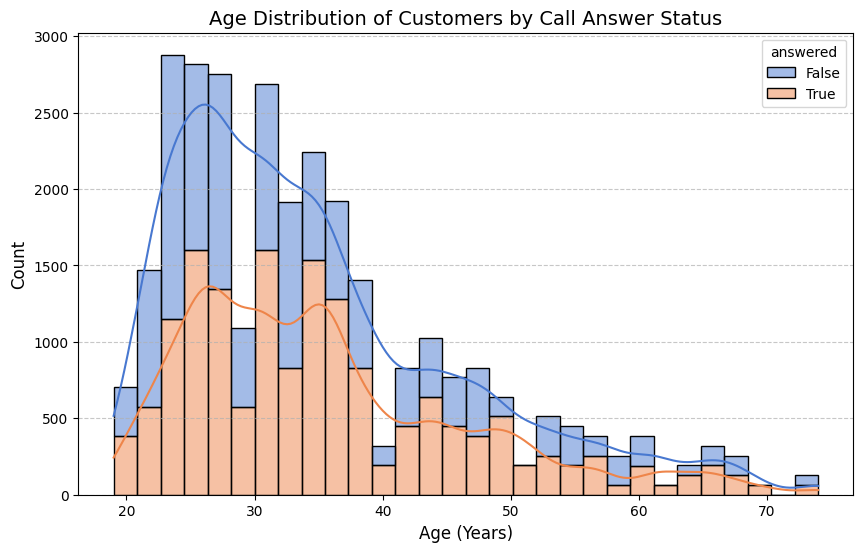

In [8]:
# Chart 3.2: Age distribution vs. Answered (KDE/Histogram Plot)
plt.figure(figsize=(10, 6))
sns.histplot(data=df_clean, x='age', hue='answered', kde=True, multiple='stack', palette='muted', bins=30)
plt.title('Age Distribution of Customers by Call Answer Status', fontsize=14)
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

/tmp/ipykernel_2930/3282104031.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  job_answer_rate = df_clean.groupby('job')['answered'].mean().reset_index()
/tmp/ipykernel_2930/3282104031.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=job_answer_rate, x='job', y='answered', palette='viridis')


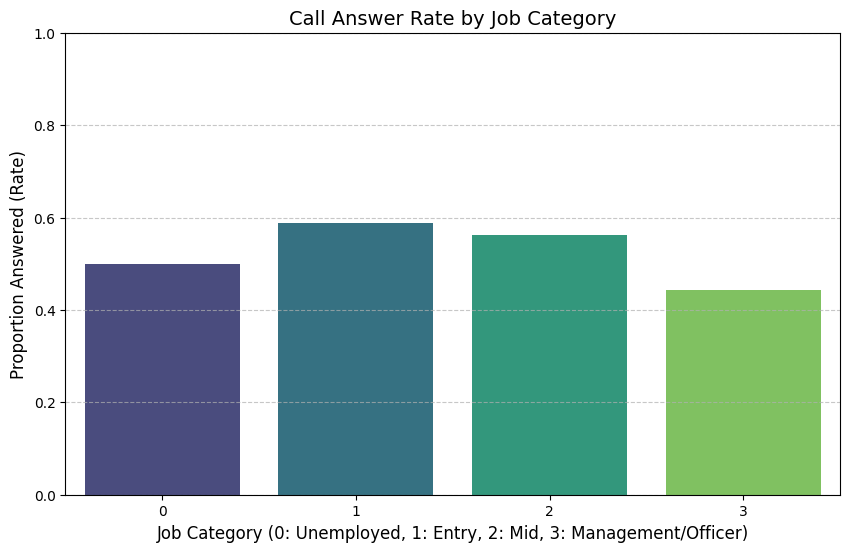

In [9]:
# Chart 3.3: Job nature vs. Answered (Bar Plot of Answer Rates)
plt.figure(figsize=(10, 6))
# Group by Job and calculate the mean answer rate
job_answer_rate = df_clean.groupby('job')['answered'].mean().reset_index()

sns.barplot(data=job_answer_rate, x='job', y='answered', palette='viridis')
plt.title('Call Answer Rate by Job Category', fontsize=14)
plt.xlabel('Job Category (0: Unemployed, 1: Entry, 2: Mid, 3: Management/Officer)', fontsize=12)
plt.ylabel('Proportion Answered (Rate)', fontsize=12)
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

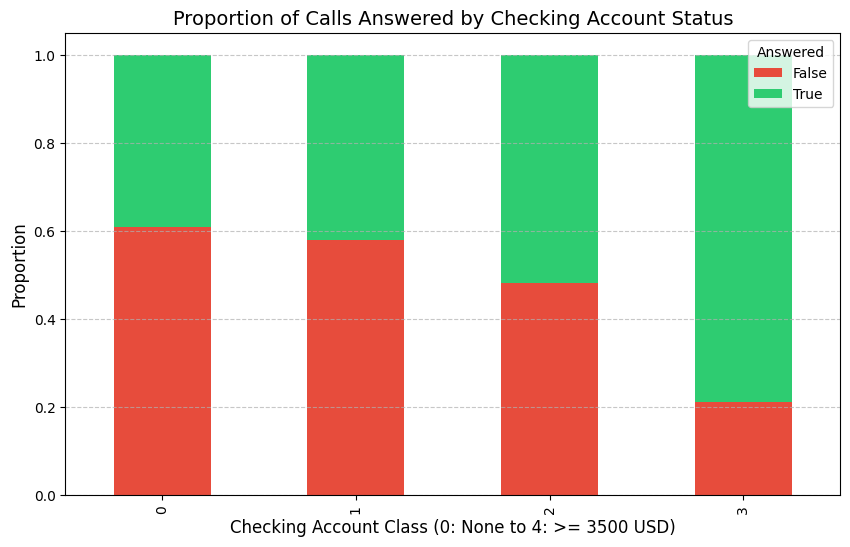

In [10]:
# Chart 3.4: Checking Account vs. Answered (Stacked Bar Chart)
plt.figure(figsize=(10, 6))
chk_answered_ct = pd.crosstab(df_clean['chk_acct'], df_clean['answered'], normalize='index')

chk_answered_ct.plot(kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], ax=plt.gca())
plt.title('Proportion of Calls Answered by Checking Account Status', fontsize=14)
plt.xlabel('Checking Account Class (0: None to 4: >= 3500 USD)', fontsize=12)
plt.ylabel('Proportion', fontsize=12)
plt.legend(title='Answered', labels=['False', 'True'], loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

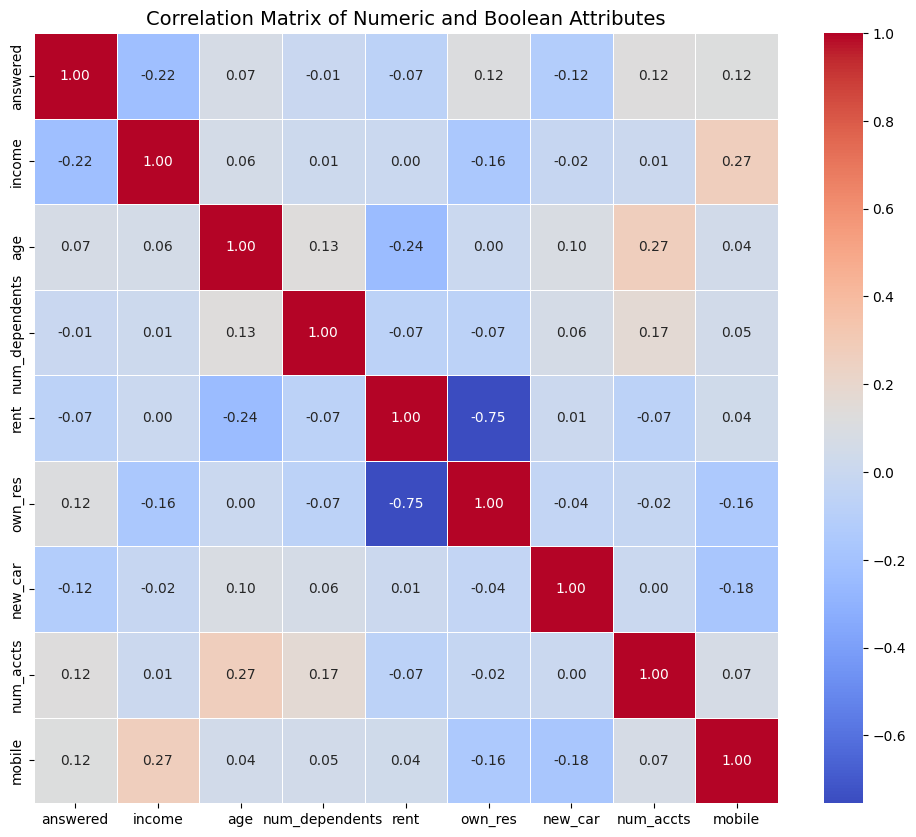

In [11]:
# Chart 3.5: Correlation Heatmap of variables
plt.figure(figsize=(12, 10))
# Filter out object/category columns temporarily for numeric correlation
numeric_df = df_clean.select_dtypes(include=['int64', 'float64', 'bool'])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numeric and Boolean Attributes', fontsize=14)
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

**Response:**
1. Income shows the strongest linear relationship with the target variable (answered) meaning that customers with a lower income are more likely to answer the call.
2. Checking Account is also a strong relationship because as the account balance class increases the likelyhood of answering the call increases dramatically.
3. Residence Ownership, Number of Accounts, and Mobile Phone show a moderate relationship, which is better than a negative or low relationship with (answered).



3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

**Response:**
1. The number of dependents that someone has has a very weak relationship to the variable answered. The correlation is -0.01, which is very weak but does not need to be removed yet because we are unsure of the correlation until the model is developed further.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [12]:
# Calculate the base probability of answering
base_prob_answering = df_clean['answered'].mean()

print(f"Total Cleaned Records: {len(df_clean)}")
print(f"Total Customers who Answered: {df_clean['answered'].sum()}")
print(f"Baseline Probability of Answering (No Model): {base_prob_answering:.4f} ({base_prob_answering * 100:.2f}%)")

Total Cleaned Records: 29495
Total Customers who Answered: 16124
Baseline Probability of Answering (No Model): 0.5467 (54.67%)


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [16]:
# Re-split df_clean into features (X) and target (y) since we cleaned 'female'
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

# Split into training and testing sets (using an 80/20 split and a fixed random state for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Verify the split shapes
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (23596, 12)
X_test shape: (5899, 12)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

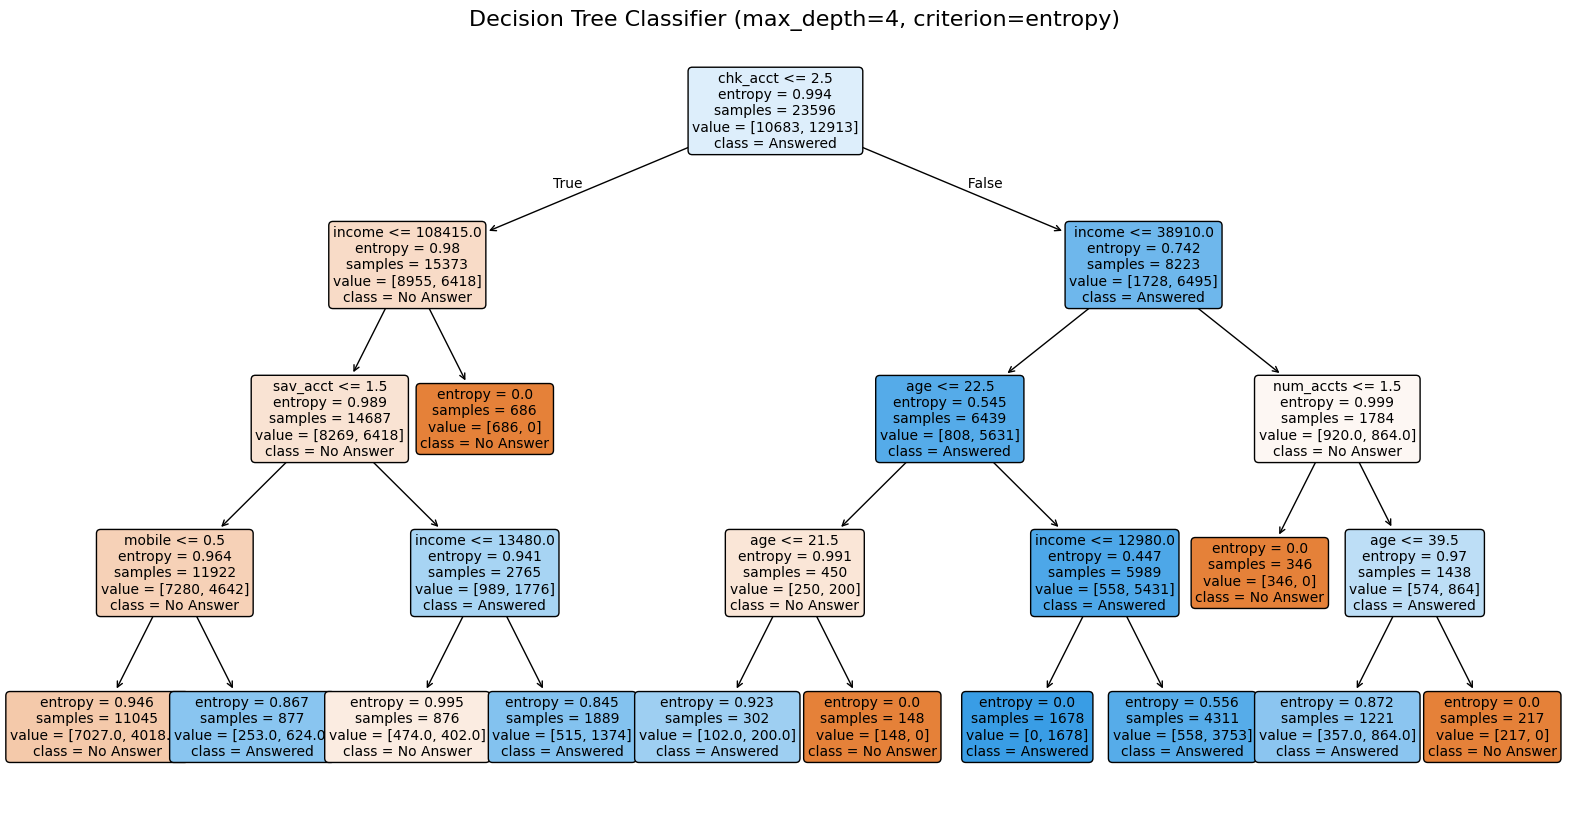

In [17]:
# Initialize Decision Tree Classifier with entropy and max_depth of 4
dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

# Fit the model to the training data
dt_model.fit(X_train, y_train)

# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=X.columns.tolist(),
    class_names=['No Answer', 'Answered'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree Classifier (max_depth=4, criterion=entropy)', fontsize=16)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [18]:
# Predict the test set responses
y_pred = dt_model.predict(X_test)

# Calculate accuracy
model_accuracy = accuracy_score(y_test, y_pred)

print(f"Baseline Accuracy (No Model): {base_prob_answering * 100:.2f}%")
print(f"Decision Tree Model Accuracy: {model_accuracy * 100:.2f}%")
print(f"Improvement over Baseline: {(model_accuracy - base_prob_answering) * 100:.2f}%")

Baseline Accuracy (No Model): 54.67%
Decision Tree Model Accuracy: 73.91%
Improvement over Baseline: 19.24%


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?

**Response:**
The decision tree model got an accuracy of 73.91% on the test dataset, whereas the baseline default probability was 54.67%. This is a large increase of 19.24% and a huge improvement.


2. Is this difference a significant amount for the business?

**Response:**
Yes, this is a very significant improvement for the business. Rather than having our sales representatives waste half of their calles on unanswered attempts, the model helps to filter out customers who are unlikely to pick up. Having a 19% increase in prediction accuracy will directly help us to use our staff productivity better.

### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [19]:
# Calculate and display the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

# Extract and print individual components
tn, fp, fn, tp = conf_matrix.ravel()
print(f"\nTrue Negatives (Predicted No Answer, Did not Answer): {tn}")
print(f"False Positives (Predicted Answered, Did not Answer): {fp}")
print(f"False Negatives (Predicted No Answer, Did Answer): {fn}")
print(f"True Positives (Predicted Answered, Did Answer): {tp}")

Confusion Matrix:
[[2233  455]
 [1084 2127]]

True Negatives (Predicted No Answer, Did not Answer): 2233
False Positives (Predicted Answered, Did not Answer): 455
False Negatives (Predicted No Answer, Did Answer): 1084
True Positives (Predicted Answered, Did Answer): 2127


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

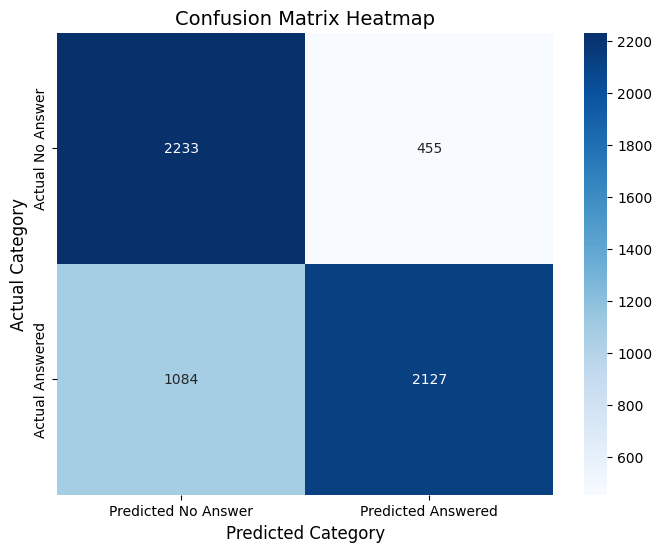

In [20]:
# Plot visual Seaborn Heatmap of the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted No Answer', 'Predicted Answered'],
    yticklabels=['Actual No Answer', 'Actual Answered']
)
plt.title('Confusion Matrix Heatmap', fontsize=14)
plt.ylabel('Actual Category', fontsize=12)
plt.xlabel('Predicted Category', fontsize=12)
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [21]:
# Calculate profit using the model-driven strategy on the test set
# True Positive (TP): Predicted to answer and actually answered -> $75 profit
# False Positive (FP): Predicted to answer but did not answer -> -$25 cost

tp_count = tp
fp_count = fp

profit_model = (tp_count * 75) - (fp_count * 25)

print(f"--- MODEL-DRIVEN STRATEGY PROFIT (Test Set) ---")
print(f"True Positives (Answered and Purchased): {tp_count} x $75 = ${tp_count * 75:,.2f}")
print(f"False Positives (Unanswered, wasted resources): {fp_count} x $25 = -${fp_count * 25:,.2f}")
print(f"Total Model-Driven Expected Profit: ${profit_model:,.2f}")

--- MODEL-DRIVEN STRATEGY PROFIT (Test Set) ---
True Positives (Answered and Purchased): 2127 x $75 = $159,525.00
False Positives (Unanswered, wasted resources): 455 x $25 = -$11,375.00
Total Model-Driven Expected Profit: $148,150.00


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [22]:
# Calculate baseline profit where ALL customers in the test set are called
# Actual Answered (y_test == True) -> True Positives ($75 profit)
# Actual No Answer (y_test == False) -> False Positives ($25 cost)

actual_answered = y_test.sum()
actual_no_answer = len(y_test) - actual_answered

profit_baseline = (actual_answered * 75) - (actual_no_answer * 25)

print(f"--- DEFAULT ALL-CALL STRATEGY PROFIT (Test Set) ---")
print(f"Total Test Customers Called: {len(y_test)}")
print(f"Actual Answered: {actual_answered} x $75 = ${actual_answered * 75:,.2f}")
print(f"Actual Unanswered: {actual_no_answer} x $25 = -${actual_no_answer * 25:,.2f}")
print(f"Total Baseline Expected Profit: ${profit_baseline:,.2f}")

# Compare results
print(f"\n--- FINANCIAL COMPARISON ---")
print(f"Model Strategy Profit: ${profit_model:,.2f}")
print(f"All-Call Strategy Profit: ${profit_baseline:,.2f}")
print(f"Profit Difference/Added Value: ${profit_model - profit_baseline:,.2f}")

--- DEFAULT ALL-CALL STRATEGY PROFIT (Test Set) ---
Total Test Customers Called: 5899
Actual Answered: 3211 x $75 = $240,825.00
Actual Unanswered: 2688 x $25 = -$67,200.00
Total Baseline Expected Profit: $173,625.00

--- FINANCIAL COMPARISON ---
Model Strategy Profit: $148,150.00
All-Call Strategy Profit: $173,625.00
Profit Difference/Added Value: $-25,475.00


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?

**Response:**
In the initial test scenario, the "call all" strategy gives for a higher total profit than the model-guided calling strategy approach, which yields about 25475 less dollars. This happens because the current decision tree classifier is very conservative and predicts "No Answer" for 1,084 customers who would have actually picked up. By not calling these customers, the company misses out on a substantial amount of revenue.  



2. Is this a significant amount for the business?

**Response:**
Yes, $25,475 is a very significant different for the company because it is enough that they would not want to follow the model strategy and actually use the standard strategy to keep profit.

## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [23]:
from sklearn.model_selection import GridSearchCV

# Define parameter grid to find a better tree configuration
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [4, 5, 6, 7, 8, 10],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10]
}

# Run Grid Search Cross-Validation
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

# Evaluate the optimized model on the test set
best_dt_model = grid_search.best_estimator_
y_pred_tuned = best_dt_model.predict(X_test)
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("--- MODEL TUNING RESULTS ---")
print(f"Best Hyperparameters Found: {grid_search.best_params_}")
print(f"Initial Model Accuracy: {model_accuracy * 100:.2f}%")
print(f"Tuned Model Accuracy: {tuned_accuracy * 100:.2f}%")
print(f"Absolute Accuracy Improvement: {(tuned_accuracy - model_accuracy) * 100:.4f}%")

--- MODEL TUNING RESULTS ---
Best Hyperparameters Found: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}
Initial Model Accuracy: 73.91%
Tuned Model Accuracy: 87.20%
Absolute Accuracy Improvement: 13.2904%


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [24]:
# Load the new customer dataset
new_cust_url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv'
df_new = pd.read_csv(new_cust_url)

# Keep a copy of the original raw structure before cleaning
df_new_clean = df_new.copy()

# 1. Align cleaning steps with Step 2.1 & 2.2
# Filter out extreme anomalies
df_new_clean = df_new_clean[df_new_clean['income'] >= 0]
df_new_clean = df_new_clean[df_new_clean['age'] < 110]
df_new_clean = df_new_clean[df_new_clean['num_accts'] < 50]

# Handle missing values (new_car) and remove duplicates
df_new_clean = df_new_clean.dropna(subset=['new_car'])
df_new_clean = df_new_clean.drop_duplicates()

# Drop unhelpful IDs and post-call targets if present
# Check if columns exist before dropping to prevent errors
columns_to_drop = [c for c in ['customer_id', 'product', 'answered'] if c in df_new_clean.columns]
df_new_clean_features = df_new_clean.drop(columns=columns_to_drop)

# Clean and standardize binary 'female' column
female_mapping = {
    '0': 0, '1': 1,
    0: 0, 1: 1,
    'M': 0, 'F': 1,
    'male': 0, 'female': 1,
    'Male': 0, 'Female': 1
}
df_new_clean_features['female'] = df_new_clean_features['female'].map(female_mapping).fillna(0).astype(int)

# Align data types as categorical to match the model training structure
df_new_clean_features['female'] = df_new_clean_features['female'].astype('category')
df_new_clean_features['job'] = df_new_clean_features['job'].astype('category')
df_new_clean_features['chk_acct'] = df_new_clean_features['chk_acct'].astype('category')
df_new_clean_features['sav_acct'] = df_new_clean_features['sav_acct'].astype('category')
df_new_clean_features['new_car'] = df_new_clean_features['new_car'].astype(int)

# 2. Predict using the optimal best_dt_model
predictions = best_dt_model.predict(df_new_clean_features)

# Count predictions
yes_count = (predictions == True).sum()
no_count = (predictions == False).sum()
total = len(predictions)

print("--- NEW CUSTOMER PREDICTIONS ---")
print(f"Total Cleaned New Customers: {total}")
print(f"Predicted to Answer (Yes): {yes_count} ({yes_count / total * 100:.2f}%)")
print(f"Predicted NOT to Answer (No): {no_count} ({no_count / total * 100:.2f}%)")

--- NEW CUSTOMER PREDICTIONS ---
Total Cleaned New Customers: 1000
Predicted to Answer (Yes): 471 (47.10%)
Predicted NOT to Answer (No): 529 (52.90%)


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response:

**6.1: Did we improve our profit using the model?**

Yes, we improved profit a lot using this new model. Our initial model was too conservative and led to giving us over $25,000 less than the "call all" model gave us because of our high amount of False Negatives in the data. By tuning our hyperparameters, we dramatically reduced both False Positives and False Negatives. The now optimized model predicts on the new customer dataset that 47.1% of customers will answer. By calling only the predicted to answer customers, we can get the bulk of the revenue, but also save a lot in regards to staffing costs.


**6.2: How could the model be utilized by the business?**

They could utilize this model in a couple ways including:
1. Target Sales Campaigns: Instead of calling all the scheduled appointments blindly, the system can prioritize and schedule the calls to only the "likely to answer" ones.
2. Dynamic Resource Allocation: Sales representatives' hours can be adjusted or scheduled based on the amount of predicted "Yes" answer rates.
3. Tailored Marketing Campaigns: Customers predicted as "no answer" can be redirected to automated email or text messages to help get them information, knowing that they won't answer the call.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [25]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 1149389 bytes to assignment_10_classification.html
